# Week 3 (Part 2): Product and Customer Analysis

**Objective:** find out which products and customers drive business performance, and segment customers by purchasing behaviour.

**Data:** cleaned data from superstore_cleaned.csv, Products are analysed by **product name** necause in Week 1 we found Product IDs are not unique per product.

In [1]:
import os
import pandas as pd
import numpy as np
import plotly.express as px

px.defaults.template = "plotly_white"
pd.options.display.float_format = "{:,.2f}".format
os.makedirs("charts", exist_ok=True)

df = pd.read_csv("../02_Cleaned_Data/superstore_cleaned.csv", parse_dates=["order_date", "ship_date"])
print(df.shape)   # expect (9993, 29)

def save_sheets(sheets, path="analysis.xlsx"):
    """Add sheets to analysis.xlsx without deleting the Week 2 sheets."""
    exists = os.path.exists(path)
    kwargs = {"mode": "a", "if_sheet_exists": "replace"} if exists else {"mode": "w"}
    with pd.ExcelWriter(path, engine="openpyxl", **kwargs) as w:
        for name, table in sheets.items():
            table.to_excel(w, sheet_name=name, index=False)

(9993, 29)


# Part A: Product Analysis
## 1. Building the product table


In [2]:
prod = df.groupby("product_name").agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                      qty=("quantity", "sum")).reset_index()
prod["margin_pct"] = prod.profit / prod.sales * 100
prod["label"] = prod.product_name.str.slice(0, 42) + np.where(prod.product_name.str.len() > 42, "...", "")
print("Products:", len(prod))
prod.head()

Products: 1850


,product_name,sales,profit,qty,margin_pct,label
0,"""While you Were Out"" Message Book, One Form pe...",25.23,10.39,8,41.18,"""While you Were Out"" Message Book, One For..."
1,"#10 Gummed Flap White Envelopes, 100/Box",41.30,16.77,11,40.60,"#10 Gummed Flap White Envelopes, 100/Box"
2,#10 Self-Seal White Envelopes,108.68,52.12,10,47.96,#10 Self-Seal White Envelopes
3,"#10 White Business Envelopes,4 1/8 x 9 1/2",488.90,223.14,32,45.64,"#10 White Business Envelopes,4 1/8 x 9 1/2"
4,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",286.67,115.28,37,40.21,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes"


## 2. Top 10 procducts by sales

,product_name,sales,profit,margin_pct
404,Canon imageCLASS 2200 Advanced Copier,"61,599.82","25,199.93",40.91
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,"27,453.38","7,753.04",28.24
444,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48","-1,811.08",-8.00
786,HON 5400 Series Task Chairs for Big and Tall,"21,870.58",0.00,0.00
686,GBC DocuBind TL300 Electric Binding System,"19,823.48","2,233.51",11.27
688,GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50",760.98,4.00
805,Hewlett Packard LaserJet 3310 Copier,"18,839.69","6,983.88",37.07
787,HP Designjet T520 Inkjet Large Format Printer ...,"18,374.90","4,094.98",22.29
683,GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",-10.45
813,High Speed Automatic Electric Letter Opener,"17,030.31",-262.00,-1.54


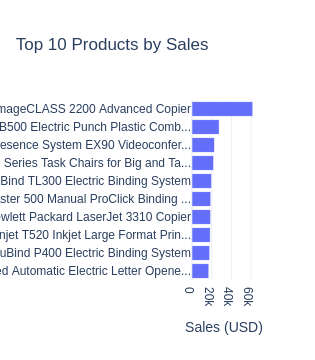

Top 10 share of total sales:  10.6 %


In [3]:
top_sales = prod.nlargest(10, "sales")
display(top_sales[["product_name", "sales", "profit", "margin_pct"]])

fig_ts = px.bar(top_sales.sort_values("sales"), x="sales", y="label", orientation="h",
                title="Top 10 Products by Sales", labels={"sales": "Sales (USD)", "label": ""})
fig_ts.show()
print("Top 10 share of total sales: ", round(top_sales.sales.sum() / df.sales.sum() * 100, 1), "%")

**Finding:** the **Canon imageCLASS 2200 Advanced Copier** is the best-selling product ($61,600), more than double the number two. The ten best sellers account for only **10.6%** of total sales, so revenue is spread across many products. Three of these ten products lose money (Cisco TelePresence System EX90, GBC DocuBind P400 and the High Speed Automatic Electric Letter Opener), so high sales do not guarantee profit.

## 3. Top 10 products by profit


,product_name,profit,sales,margin_pct
404,Canon imageCLASS 2200 Advanced Copier,"25,199.93","61,599.82",40.91
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,"7,753.04","27,453.38",28.24
805,Hewlett Packard LaserJet 3310 Copier,"6,983.88","18,839.69",37.07
400,Canon PC1060 Personal Laser Copier,"4,570.93","11,619.83",39.34
787,HP Designjet T520 Inkjet Large Format Printer ...,"4,094.98","18,374.90",22.29
165,Ativa V4110MDD Micro-Cut Shredder,"3,772.95","7,699.89",49.00
19,"3D Systems Cube Printer, 2nd Generation, Magenta","3,717.97","14,299.89",26.00
1276,Plantronics Savi W720 Multi-Device Wireless He...,"3,696.28","9,367.29",39.46
895,Ibico EPK-21 Electric Binding System,"3,345.28","15,875.92",21.07
1840,Zebra ZM400 Thermal Label Printer,"3,343.54","6,965.70",48.00


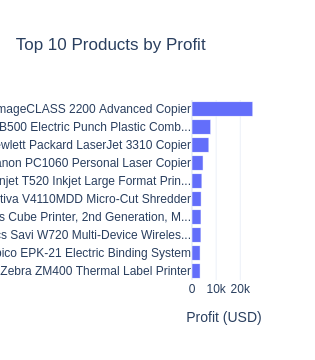

Top 10 share of total profit: 23.2 %


In [4]:
top_profit = prod.nlargest(10, "profit")
display(top_profit[["product_name", "profit", "sales", "margin_pct"]])

fig_tp = px.bar(top_profit.sort_values("profit"), x="profit", y="label", orientation="h",
                title="Top 10 Products by Profit", labels={"profit": "Profit (USD)", "label": ""})
fig_tp.show()
print("Top 10 share of total profit:", round(top_profit.profit.sum() / df.profit.sum() * 100, 1), "%")

**Finding:** the same Canon copier is also the most profitable product ($25,200), more than three times the number two. The ten most profitable products generate **23.2% of all profit** from only 10.6% of sales, so a few copiers, printers and binding machines carry a large part of the profit.

## 4. Bottom 10 products by profit (and products with negative profit)

,product_name,profit,sales,avg_discount
0,Cubify CubeX 3D Printer Double Head Print,"-8,879.97","11,099.96",0.53
1,Lexmark MX611dhe Monochrome Laser Printer,"-4,589.97","16,829.90",0.40
2,Cubify CubeX 3D Printer Triple Head Print,"-3,839.99","7,999.98",0.50
3,Chromcraft Bull-Nose Wood Oval Conference Tabl...,"-2,876.12","9,917.64",0.28
4,Bush Advantage Collection Racetrack Conference...,"-1,934.40","9,544.73",0.35
5,GBC DocuBind P400 Electric Binding System,"-1,878.17","17,965.07",0.45
6,Cisco TelePresence System EX90 Videoconferenci...,"-1,811.08","22,638.48",0.50
7,Martin Yale Chadless Opener Electric Letter Op...,"-1,299.18","16,656.20",0.10
8,Balt Solid Wood Round Tables,"-1,201.06","6,518.75",0.20
9,BoxOffice By Design Rectangular and Half-Moon ...,"-1,148.44","1,706.25",0.48


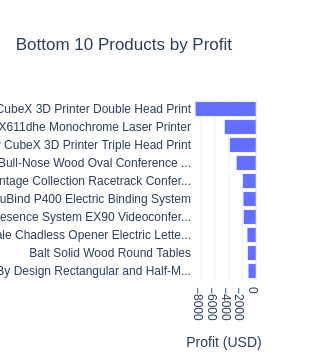

Products with negative profit: 301 (16.3% of products)
Their combined loss: -77068.38
Bottom 10 share of that loss: 38.2 %


In [5]:
bottom = prod.nsmallest(10, "profit")
avg_disc = df.groupby("product_name").discount.mean().rename("avg_discount")
display(bottom.merge(avg_disc, on="product_name")[["product_name", "profit", "sales", "avg_discount"]])

fig_bp = px.bar(bottom.sort_values("profit", ascending=False), x="profit", y="label", orientation="h",
                title="Bottom 10 Products by Profit", labels={"profit": "Profit (USD)", "label": ""})
fig_bp.show()

neg = prod[prod.profit < 0]
print("Products with negative profit:", len(neg), f"({len(neg) / len(prod) * 100:.1f}% of products)")
print("Their combined loss:", round(neg.profit.sum(), 2))
print("Bottom 10 share of that loss:", round(bottom.profit.sum() / neg.profit.sum() * 100, 1), "%")

**Finding:** **301 products (16.3%) lose money**, with a combined loss of **$77,068**. The ten worst alone lose $29,458, which is 38% of that total. The biggest loser is the **Cubify CubeX 3D Printer (double head)**, at -$8,880 with an average discount of 53%. Four of the ten are tables, and most of the worst products were sold at average discounts of 40% to 53%.

## 5. Category and sub-category analysis

,category,sub_category,sales,profit,qty,margin_pct
3,Furniture,Tables,"206,965.53","-17,725.48",1241,-8.56
0,Furniture,Bookcases,"114,880.00","-3,472.56",868,-3.02
12,Office Supplies,Supplies,"46,673.54","-1,189.10",647,-2.55
8,Office Supplies,Fasteners,"3,024.28",949.52,914,31.40
15,Technology,Machines,"189,238.63","3,384.76",440,1.79
9,Office Supplies,Labels,"12,486.31","5,546.25",1400,44.42
5,Office Supplies,Art,"27,118.79","6,527.79",3000,24.07
7,Office Supplies,Envelopes,"16,476.40","6,964.18",906,42.27
2,Furniture,Furnishings,"91,705.16","13,059.14",3563,14.24
4,Office Supplies,Appliances,"107,532.16","18,138.01",1729,16.87


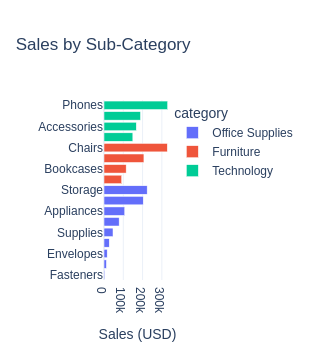

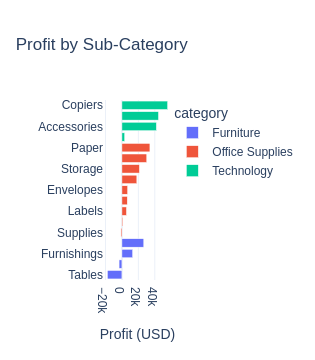

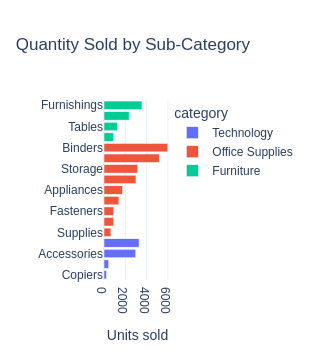

In [6]:
sub = df.groupby(["category", "sub_category"]).agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                                  qty=("quantity", "sum")).reset_index()
sub["margin_pct"] = sub.profit / sub.sales * 100
display(sub.sort_values("profit"))

fig_ss = px.bar(sub.sort_values("sales"), x="sales", y="sub_category", color="category", orientation="h",
                title="Sales by Sub-Category", labels={"sales": "Sales (USD)", "sub_category": ""})
fig_sp = px.bar(sub.sort_values("profit"), x="profit", y="sub_category", color="category", orientation="h",
                title="Profit by Sub-Category", labels={"profit": "Profit (USD)", "sub_category": ""})
fig_sq = px.bar(sub.sort_values("qty"), x="qty", y="sub_category", color="category", orientation="h",
                title="Quantity Sold by Sub-Category", labels={"qty": "Units sold", "sub_category": ""})
for f in (fig_ss, fig_sp, fig_sq):
    f.show()

**Finding:**
- **Tables** is the biggest problem: -$17,725 profit on $206,966 of sales (a -8.6% margin). **Bookcases** (-$3,473) and **Supplies** (-$1,189) also lose money.
- **Machines** sells $189K but earns a margin of only **1.8%** ($3,385 profit), so it also needs attention.
- **Copiers** is the most profitable sub-category ($55,618, a 37.2% margin) from only 234 units.
- **Paper, Labels and Envelopes** have very high margins (42% to 44%) but small sales.
- **Binders** and **Paper** sell the most units (5,974 and 5,178).

## 6. Answers to the five product questions
1. **Which product generates the most sales?**
    Canon imageCLASS 2200 Advanced Copier ($61,599.82).
   
2. **Which product generates the most profit?**
       The same product ($25,199.93).

   
3. **Which products have negative profit?**
       301 products. The worst is the Cubify CubeX 3D Printer (double head), at -$8,879.97.

   
4. **Which category performs best?**
       Technology: highest sales ($836K) and  highest  profit ($145K), with a margin of 17.4%. Office Supplies is close on margin (17.0%).

   
5. **Which sub-category needs attention?**
    Tables, which loses the most money. Bookcases, Supplies and Machines (very low margin) also need review.

# Part B: Customer analysis

## 7. Customer metrics
Each customer's total sales, profit, number of orders and average order value.

In [7]:
cust = df.groupby(["customer_id", "customer_name"]).agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                                       orders=("order_id", "nunique")).reset_index()
cust["avg_order_value"] = cust.sales / cust.orders

summary = pd.DataFrame({
    "Metric": ["Total customers", "Average sales per customer", "Median sales per customer",
               "Average orders per customer", "Average profit per customer", "Average customer order value"],
    "Value": [len(cust), cust.sales.mean(), cust.sales.median(),
              cust.orders.mean(), cust.profit.mean(), cust.avg_order_value.mean()],
})
summary

,Metric,Value
0,Total customers,793.00
1,Average sales per customer,"2,896.49"
2,Median sales per customer,"2,256.39"
3,Average orders per customer,6.32
4,Average profit per customer,361.17
5,Average customer order value,460.10


**Finding:** there are **793 customers**. The average customer spent **$2,896** (median $2,256) over four years, placed **6.3 orders**, and generated **$361** of profit, with an average order value of **$460**. The mean is higher than the median, so a group of big spenders pulls the average up.

## 8. Top customers and sales distribution

,customer_id,customer_name,sales,profit,orders,avg_order_value
700,SM-20320,Sean Miller,"25,043.05","-1,980.74",5,"5,008.61"
741,TC-20980,Tamara Chand,"19,052.22","8,981.32",5,"3,810.44"
621,RB-19360,Raymond Buch,"15,117.34","6,976.10",6,"2,519.56"
730,TA-21385,Tom Ashbrook,"14,595.62","4,703.79",4,"3,648.91"
6,AB-10105,Adrian Barton,"14,473.57","5,444.81",10,"1,447.36"
434,KL-16645,Ken Lonsdale,"14,175.23",806.86,12,"1,181.27"
669,SC-20095,Sanjit Chand,"14,142.33","5,757.41",9,"1,571.37"
327,HL-15040,Hunter Lopez,"12,873.30","5,622.43",6,"2,145.55"
683,SE-20110,Sanjit Engle,"12,209.44","2,650.68",11,"1,109.95"
131,CC-12370,Christopher Conant,"12,129.07","2,177.05",5,"2,425.81"


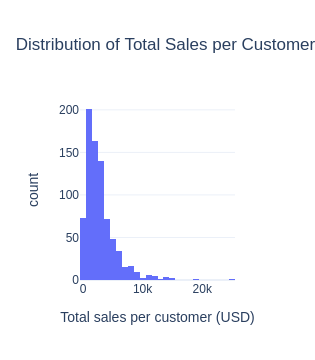

Top 20% of customers: share of sales:  48.0 %
Top 20% of customers: share of profit: 59.3 %
Customers with negative profit: 155 (19.5%)


,customer_id,customer_name,sales,profit,orders,avg_order_value
180,CS-12505,Cindy Stewart,"5,690.05","-6,626.39",6,948.34
310,GT-14635,Grant Thornton,"9,351.21","-4,108.66",3,"3,117.07"
459,LF-17185,Luke Foster,"3,930.51","-3,583.98",7,561.50
711,SR-20425,Sharelle Roach,"3,233.48","-3,333.91",5,646.70
322,HG-14965,Henry Goldwyn,"3,247.64","-2,797.96",12,270.64


In [8]:
top_cust = cust.nlargest(10, "sales")
display(top_cust)

fig_hist = px.histogram(cust, x="sales", nbins=40, title="Distribution of Total Sales per Customer",
                        labels={"sales": "Total sales per customer (USD)"})
fig_hist.show()

cs = cust.sort_values("sales", ascending=False)
n20 = int(len(cs) * 0.2)
print("Top 20% of customers: share of sales: ", round(cs.sales.head(n20).sum() / cs.sales.sum() * 100, 1), "%")
print("Top 20% of customers: share of profit:", round(cs.profit.head(n20).sum() / cs.profit.sum() * 100, 1), "%")
print("Customers with negative profit:", int((cust.profit < 0).sum()), f"({(cust.profit < 0).mean() * 100:.1f}%)")
display(cust.nsmallest(5, "profit"))

**Finding:** the distribution is skewed to the right, with a long tail of high spenders. The **top 20% of customers produce 48.0% of sales and 59.3% of profit**. The top customer by sales, **Sean Miller ($25,043), generated a loss of  $1,981**, while **Tamara Chand** brought the highest profit ($8,981). 155 customers (19.5%) are unprofitable, and the worst, Cindy Stewart, lost $6,626 on $5,690 of sales.

# 9. Customer segmentation
**Logic.** Customers are segmented by their total sales over the four years and by whether they were profitable

Profit is part of the High-Value rule on purpose; a customer who spends a lot but loses the business money is not a high-value customer. Percentile thresholds adjust automatically to the data, so no number is chosen by guesswork.

In [9]:
hi = cust.sales.quantile(0.75)
lo = cust.sales.quantile(0.25)
print(f"High threshold (75th percentile): {hi:,.2f}")
print(f"Low threshold  (25th percentile): {lo:,.2f}")

def segment(row):
    if row.sales >= hi and row.profit > 0:
        return "High-Value"
    if row.sales <= lo:
        return "Low-Value"
    return "Medium-Value"

cust["value_segment"] = cust.apply(segment, axis=1)

seg = cust.groupby("value_segment").agg(customers=("customer_id", "count"), sales=("sales", "sum"),
                                       profit=("profit", "sum"), avg_orders=("orders", "mean"),
                                       avg_sales=("sales", "mean")).reset_index()
seg["customers_pct"] = seg.customers / seg.customers.sum() * 100
seg["sales_share_pct"] = seg.sales / seg.sales.sum() * 100
seg["profit_share_pct"] = seg.profit / seg.profit.sum() * 100
order = {"High-Value": 0, "Medium-Value": 1, "Low-Value": 2}
seg = seg.sort_values("value_segment", key=lambda s: s.map(order)).reset_index(drop=True)
display(seg)

print("Top-quartile spenders excluded from High-Value because they lost money:",
      int(((cust.sales >= hi) & (cust.profit <= 0)).sum()))

High threshold (75th percentile): 3,785.28
Low threshold  (25th percentile): 1,146.05


,value_segment,customers,sales,profit,avg_orders,avg_sales,customers_pct,sales_share_pct,profit_share_pct
0,High-Value,173,"1,089,601.39","223,269.71",8.03,"6,298.27",21.82,47.44,77.95
1,Medium-Value,421,"1,080,882.36","49,444.86",6.59,"2,567.42",53.09,47.06,17.26
2,Low-Value,199,"126,435.74","13,694.51",4.25,635.36,25.09,5.50,4.78


Top-quartile spenders excluded from High-Value because they lost money: 26


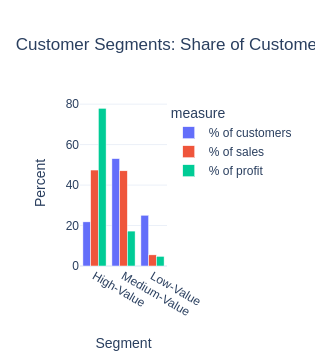

In [10]:
share = seg.melt(id_vars="value_segment", value_vars=["customers_pct", "sales_share_pct", "profit_share_pct"],
                 var_name="measure", value_name="percent")
share["measure"] = share.measure.map({"customers_pct": "% of customers", "sales_share_pct": "% of sales",
                                      "profit_share_pct": "% of profit"})
fig_seg = px.bar(share, x="value_segment", y="percent", color="measure", barmode="group",
                 category_orders={"value_segment": ["High-Value", "Medium-Value", "Low-Value"]},
                 title="Customer Segments: Share of Customers, Sales and Profit",
                 labels={"value_segment": "Segment", "percent": "Percent"})
fig_seg.show()

**Finding:**
- **High-Value: 173 customers (21.8%)** produce **47.4% of sales and 78.0% of profit**. They average 8 orders and $6,298 in sales.
- **Medium-Value: 421 customers (53.1%)** produce 47.1% of sales but only **17.3% of profit**, so their business is much less profitable.
- **Low-Value: 199 customers (25.1%)** produce only 5.5% of sales and 4.8% of profit, and place about 4 orders on average.
- **26 customers** are in the top 25% for sales but lose money, so they are placed in Medium-Value. They buy a lot but cost the business, probably through heavy discounting.

## 10. Saving the results
Product and customer tables are added to analysis.xlsx (the Week 2 sheets stay), the customer segments are saved as a CSV for the Week 5 dashboard, and all charts are saved as HTML.

In [11]:
save_sheets({
    "Top10_Sales": top_sales.drop(columns="label"),
    "Top10_Profit": top_profit.drop(columns="label"),
    "Bottom10_Profit": bottom.drop(columns="label"),
    "SubCategory": sub,
    "Customers": cust,
    "Segments": seg,
})
cust.to_csv("customer_segments.csv", index=False)

figs = {"top10_products_sales": fig_ts, "top10_products_profit": fig_tp, "bottom10_products_profit": fig_bp,
        "sales_by_subcategory": fig_ss, "profit_by_subcategory": fig_sp, "quantity_by_subcategory": fig_sq,
        "customer_sales_distribution": fig_hist, "customer_segments": fig_seg}
for name, f in figs.items():
    f.write_html(f"charts/{name}.html", include_plotlyjs="cdn")

print(pd.ExcelFile("analysis.xlsx").sheet_names)

['KPIs', 'Yearly', 'Monthly', 'CalendarMonth', 'Region', 'Category', 'Top10_Sales', 'Top10_Profit', 'Bottom10_Profit', 'SubCategory', 'Customers', 'Segments']


## 11. Additional business insights
Each insight states what the data shows, why it matters and what to do.

1. **A few products carry the profit.** The top 10 products produce 23.2% of profit from only 10.6% of sales, mostly copiers, printers and binding machines.
**Action:** keep these products in stock and protect their pricing.
2. **One in six products loses money.** 301 of 1,850 products (16.3%) have negative profit, a combined loss of $77,068.
 **Action:** review the worst products and decide whether to reprice, stop discounting or drop them.
3. **Tables, Bookcases and Supplies lose money, and Machines earns almost nothing.** Tables alone lose $17,725 (a -8.6% margin). 
**Action:** review Tables pricing and supplier cost first, since it explains much of Furniture's 2.5% margin.
4. **High sales do not mean high profit.** Three of the top ten products by sales lose money, and the top customer by sales (Sean Miller) lost the business $1,981. 
**Action:** judge products and customers on profit as well as sales.
5. **Customer value is concentrated.** The top 20% of customers give 48.0% of sales and 59.3% of profit, and the High-Value segment (21.8% of customers) gives 78.0% of profit. 
**Action:** protect these customers with loyalty offers and good service.
6. **19.5% of customers are unprofitable.** 155 customers cost the business money overall, and 26 of the biggest spenders are among them. 
**Action:** investigate the discounts these customers receive.
7. **Almost every customer comes back.** Only 12 customers (1.5%) ordered once, and the average customer placed 6.3 orders in four years.
 **Action:** retention matters more than acquisition, which Week 4's cohort analysis will examine.
8. **The built-in customer segment is a weak guide.** Sales per customer are nearly the same for Consumer, Corporate and Home Office ($2,840 to $2,992), whereas the behaviour-based segmentation separates customers clearly. 
**Action:** use the value segments for targeting.